#### Data Import: ftv47 ATSP Dataset

We load the `ftv47.atsp` file from the TSPlib. The file uses the
**EDGE_WEIGHT_SECTION** format, where all edge weights are listed row by row
as a flat integer sequence. We parse it into an **n × n distance matrix** D,
where `D[i, j]` is the cost of traveling from city i to city j.

Note that `D[i,j] ≠ D[j,i]` in general — this is what makes the problem
**asymmetric** (ATSP).

In [19]:
import numpy as np
import re

def read_atsp(filepath):
    """
    Parses a .atsp file from TSPlib format and returns
    the distance matrix and city names.
    """
    with open(filepath, 'r') as f:
        lines = f.readlines()

    n = None
    matrix_start = False
    values = []
    name = ""

    for line in lines:
        line = line.strip()
        if line.startswith("NAME"):
            name = line.split(":")[1].strip()
        if line.startswith("DIMENSION"):
            n = int(line.split(":")[1].strip())
        if line == "EDGE_WEIGHT_SECTION":
            matrix_start = True
            continue
        if line == "EOF":
            break
        if matrix_start:
            values.extend([int(x) for x in line.split()])

    D = np.array(values).reshape(n, n)
    cities = list(range(1, n + 1))
    return D, cities, name, n

filepath = "ftv47.atsp"   # adjust path if needed
D, cities, name, N_CITIES = read_atsp(filepath)

print(f"Problem name : {name}")
print(f"Number of cities: {N_CITIES}")
print(f"Distance matrix shape: {D.shape}")
print(f"Example D[0,1] = {D[0,1]},  D[1,0] = {D[1,0]}  (asymmetric!)")

Problem name : ftv47
Number of cities: 48
Distance matrix shape: (48, 48)
Example D[0,1] = 39,  D[1,0] = 41  (asymmetric!)


#### TSP Problem Environment

We implement the TSP problem environment in Python, equivalent to the
`newTSP_bin` constructor provided on the exercise sheet. It stores the
distance matrix and provides two key methods:

- `f(permutation)`: computes the **total tour cost** by summing up edge
  distances along the permutation, including the return edge to the start
- `show(p)`: prints the tour step by step with cumulative distance

The `bitlength` is set to **40 bits per city**, giving a total gene length
of 40 × 48 = 1920 bits — matching the `newTSP_bin` specification.

In [20]:
# Python port of the R newTSP_bin environment from the exercise sheet.
# Stores the distance matrix and provides tour cost evaluation.

class TSPEnvironment:
    def __init__(self, D, cities, name, solution=None, path=None):
        self._D       = D
        self._cities  = cities
        self._name    = name
        self._n       = D.shape[0]
        # bitlength: 40 bits per city (as in newTSP_bin)
        self._bitlength  = [40] * self._n
        self._genelength = sum(self._bitlength)
        self._solution   = solution
        self._path       = path

    def name(self):        return self._name
    def dist(self):        return self._D
    def cities(self):      return self._cities
    def n(self):           return self._n
    def bitlength(self):   return self._bitlength
    def genelength(self):  return self._genelength

    def f(self, permutation, tour=True):
        """Tour cost: sum of edge distances along the permutation."""
        cost = 0
        l = len(permutation) - 1
        for i in range(l):
            cost += self._D[permutation[i], permutation[i+1]]
        if tour:
            cost += self._D[permutation[l], permutation[0]]
        return cost

    def show(self, p):
        """Print tour details step by step."""
        total = 0
        l = len(p) - 1
        for i in range(l):
            d = self._D[p[i], p[i+1]]
            total += d
            print(f"  {i+1:3d}  Length: {total:6d}  "
                  f"from: {self._cities[p[i]]:3d}  "
                  f"to: {self._cities[p[i+1]]:3d}  dist: {d}")
        d = self._D[p[l], p[0]]
        total += d
        print(f"  {l+1:3d}  Length: {total:6d}  "
              f"from: {self._cities[p[l]]:3d}  "
              f"to: {self._cities[p[0]]:3d}  dist: {d}  (return)")
        return total

# ── Instantiate the environment ───────────────────────────────────────────────
tsp = TSPEnvironment(D, cities, name)
print(f"TSP Environment '{tsp.name()}' created.")
print(f"Gene length (40 bits × {tsp.n()} cities) = {tsp.genelength()} bits")

TSP Environment 'ftv47' created.
Gene length (40 bits × 48 cities) = 1920 bits


#### Part 1: Binary-Coded GA (`genemap = "Permutation"`)

We solve the ATSP using a **binary-coded Simple Genetic Algorithm** on the
`newTSP_bin` instance. Each city is assigned a **40-bit random key**.
The `genemap = "Permutation"` decodes the genome by **sorting cities by
their key values** — the rank order of the keys defines the tour.

Operators:
- **Selection**: SUS (Stochastic Universal Sampling)
- **Crossover**: one-point crossover on the key vectors
- **Mutation**: random key replacement per city
- **Elitism**: best individual always survives

Parameters: `popsize = 250`, `generations = 500`

In [21]:
import random

# Approach from lecture (INNGA_07, slide 74):
# Each city gets a 40-bit random key. Sorting these keys by value
# gives a permutation of cities → the tour. This is the "Permutation" genemap.

def decode_binary_to_permutation(keys):
    """Sort city indices by their random key → permutation (genemap=Permutation)."""
    return list(np.argsort(keys))

def random_keys_individual(n):
    """Random 40-bit keys for n cities (represented as floats in [0, 2^40))."""
    return np.random.randint(0, 2**40, size=n).astype(float)

def fitness_binary(keys):
    """Decode keys to permutation, then evaluate tour cost (minimize)."""
    perm = decode_binary_to_permutation(keys)
    return tsp.f(perm)

def sus_selection_min(population, costs, n_select):
    """SUS for minimization: invert costs so lower cost = higher fitness."""
    fit = np.array(costs, dtype=float)
    fit = fit.max() - fit + 1e-6   # invert: lower cost → higher fitness
    fit_mean = fit.mean()
    if fit_mean == 0:
        fit = np.ones(len(fit))
    exp_num = fit / fit.mean()
    ptr = random.uniform(0, 1)
    selected, cum = [], 0.0
    for j, e in enumerate(exp_num):
        cum += e
        while cum > ptr:
            selected.append(j)
            ptr += 1
    while len(selected) < n_select:
        selected.append(random.randrange(len(population)))
    random.shuffle(selected)
    return [population[i] for i in selected[:n_select]]

def crossover_keys(p1, p2, rate=0.7):
    """One-point crossover on the random key vectors."""
    if random.random() < rate:
        pt = random.randint(1, len(p1) - 1)
        c1 = np.concatenate([p1[:pt], p2[pt:]])
        c2 = np.concatenate([p2[:pt], p1[pt:]])
        return c1, c2
    return p1.copy(), p2.copy()

def mutate_keys(x, rate=0.05):
    """Replace each key with a new random value with probability rate."""
    child = x.copy()
    for i in range(len(child)):
        if random.random() < rate:
            child[i] = np.random.randint(0, 2**40)
    return child

# ── Run Binary GA ──────────────────────────────────────────────────────────────
POPSIZE_BIN     = 250
GENERATIONS_BIN = 500
SEED = 42
random.seed(SEED); np.random.seed(SEED)

pop_bin  = [random_keys_individual(tsp.n()) for _ in range(POPSIZE_BIN)]
best_bin_cost   = np.inf
best_bin_perm   = None
stats_bin = []

for gen in range(GENERATIONS_BIN):
    costs = [fitness_binary(ind) for ind in pop_bin]
    best_idx = int(np.argmin(costs))
    if costs[best_idx] < best_bin_cost:
        best_bin_cost = costs[best_idx]
        best_bin_perm = decode_binary_to_permutation(pop_bin[best_idx])

    stats_bin.append({"min": np.min(costs), "mean": np.mean(costs)})

    parents  = sus_selection_min(pop_bin, costs, POPSIZE_BIN)
    new_pop  = [pop_bin[best_idx].copy()]  # elitism
    i = 0
    while len(new_pop) < POPSIZE_BIN:
        c1, c2 = crossover_keys(parents[i % POPSIZE_BIN],
                                 parents[(i+1) % POPSIZE_BIN])
        new_pop.extend([mutate_keys(c1), mutate_keys(c2)])
        i += 2
    pop_bin = new_pop[:POPSIZE_BIN]

print(f"Binary GA best tour cost: {best_bin_cost}")

Binary GA best tour cost: 3626


#### Part 2: Permutation-Coded GA (`genemap = "Identity"`)

We create a second instance equivalent to `newTSP` from the `xegaSelectGene`
package and solve it with a **permutation-coded GA** (`algorithm = "sgperm"`).

Here the gene **is** the permutation directly, so `genemap = "Identity"`
requires no decoding step. All operators must preserve the permutation
structure:

- **Crossover**: Order Crossover (OX) — permutation-preserving
- **Mutation**: swap mutation — randomly exchanges two cities
- **Selection**: SUS + elitism

Parameters: `popsize = 250`, `generations = 500`

In [22]:
# Uses permutations directly. Operators must preserve the permutation structure.
# Crossover: Order-Based (OX) | Mutation: Swap / Inversion (2-opt move)

def random_permutation(n):
    p = list(range(n))
    random.shuffle(p)
    return p

def ox_crossover(p1, p2):
    """Order Crossover (OX): preserves relative order from one parent."""
    n  = len(p1)
    a, b = sorted(random.sample(range(n), 2))
    child = [-1] * n
    child[a:b+1] = p1[a:b+1]
    fill = [x for x in p2 if x not in child]
    idx = 0
    for i in range(n):
        if child[i] == -1:
            child[i] = fill[idx]; idx += 1
    return child

def swap_mutation(p):
    """Randomly swap two cities in the tour."""
    child = p.copy()
    i, j = random.sample(range(len(child)), 2)
    child[i], child[j] = child[j], child[i]
    return child

def two_opt_move(p):
    """2-opt: reverse a random subtour segment (inversion operator)."""
    child = p.copy()
    i, j  = sorted(random.sample(range(len(p)), 2))
    child[i:j+1] = child[i:j+1][::-1]
    return child

def greedy_mutation(p, D, n_tries=5):
    """Greedy: try n random 2-opt moves, keep the best improvement."""
    best = p.copy()
    best_cost = tsp.f(best)
    for _ in range(n_tries):
        candidate = two_opt_move(p)
        c = tsp.f(candidate)
        if c < best_cost:
            best_cost = c
            best = candidate
    return best

# ── Generic permutation GA runner ─────────────────────────────────────────────
def run_perm_ga(mutation_fn, popsize=250, generations=500, crossrate=0.7, label=""):
    random.seed(SEED); np.random.seed(SEED)
    pop = [random_permutation(tsp.n()) for _ in range(popsize)]
    best_cost, best_perm = np.inf, None
    stats = []

    for gen in range(generations):
        costs = [tsp.f(ind) for ind in pop]
        best_idx = int(np.argmin(costs))
        if costs[best_idx] < best_cost:
            best_cost = costs[best_idx]
            best_perm = pop[best_idx].copy()

        stats.append({"min": np.min(costs), "mean": np.mean(costs)})

        parents = sus_selection_min(pop, costs, popsize)
        new_pop = [pop[best_idx].copy()]  # elitism
        i = 0
        while len(new_pop) < popsize:
            p1 = parents[i % popsize]
            p2 = parents[(i+1) % popsize]
            if random.random() < crossrate:
                c1 = ox_crossover(p1, p2)
                c2 = ox_crossover(p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            new_pop.extend([mutation_fn(c1), mutation_fn(c2)])
            i += 2
        pop = new_pop[:popsize]

    print(f"{label:30s} Best tour cost: {best_cost}")
    return best_cost, best_perm, stats

cost_perm_swap, perm_swap, stats_swap = run_perm_ga(
    swap_mutation, label="Perm-GA (swap mutation)")

Perm-GA (swap mutation)        Best tour cost: 3233


#### Part 3: Different Mutation Heuristics

Based on the permutation GA, we test three additional mutation strategies
from the lecture (INNGA_07, slides 52–55):

- **Greedy heuristic**: starting from a random city, always move to the
  nearest unvisited city — fast but start-node dependent
- **Best Greedy**: runs greedy from all 48 start nodes, returns the
  cheapest resulting tour — more expensive but better quality
- **Lin-Kernighan (2-opt)**: iteratively reverses subtour segments until
  no improvement is found — a classic local search used as mutation operator

The last two follow the **Hybrid GA** idea from the lecture:
*Simple GA + Competing Algorithm = Hybrid GA* 

Parameters: `popsize = 250`, `generations = 500`

In [23]:
# Greedy: always pick the nearest unvisited city from a random start node
# Best Greedy: try all start nodes, pick best greedy tour
# Lin-Kernighan style: iterative 2-opt improvements

def greedy_tour(D, start=0):
    """Greedy nearest-neighbor heuristic from a given start node."""
    n = D.shape[0]
    unvisited = list(range(n))
    tour = [start]
    unvisited.remove(start)
    while unvisited:
        last = tour[-1]
        # find nearest unvisited (ignore self-loops with inf mask)
        nearest = min(unvisited, key=lambda x: D[last, x])
        tour.append(nearest)
        unvisited.remove(nearest)
    return tour

def best_greedy_tour(D):
    """Best Greedy: run greedy from every start node, return cheapest tour."""
    best_tour, best_cost = None, np.inf
    for start in range(D.shape[0]):
        t = greedy_tour(D, start)
        c = tsp.f(t)
        if c < best_cost:
            best_cost, best_tour = c, t
    return best_tour, best_cost

def two_opt_improve(tour, D, max_iter=100):
    """Lin-Kernighan style: iterative 2-opt until no improvement or max_iter."""
    best = tour.copy()
    best_cost = tsp.f(best)
    improved = True
    iteration = 0
    while improved and iteration < max_iter:
        improved = False
        iteration += 1
        for i in range(1, len(best) - 1):
            for j in range(i+1, len(best)):
                candidate = best[:i] + best[i:j+1][::-1] + best[j+1:]
                c = tsp.f(candidate)
                if c < best_cost:
                    best_cost, best = c, candidate
                    improved = True
    return best, best_cost

# ── Greedy heuristic ──────────────────────────────────────────────────────────
greedy_t  = greedy_tour(D, start=0)
cost_greedy = tsp.f(greedy_t)
print(f"{'Greedy (start=0)':30s} Tour cost: {cost_greedy}")

# ── Best Greedy heuristic ──────────────────────────────────────────────────────
best_greedy_t, cost_best_greedy = best_greedy_tour(D)
print(f"{'Best Greedy':30s} Tour cost: {cost_best_greedy}")

# ── Lin-Kernighan 2-opt on Best Greedy solution ───────────────────────────────
lk_tour, cost_lk = two_opt_improve(best_greedy_t, D, max_iter=100)
print(f"{'Lin-Kernighan (2-opt)':30s} Tour cost: {cost_lk}")

# ── Perm-GA with 2-opt mutation ────────────────────────────────────────────────
cost_perm_2opt, perm_2opt, stats_2opt = run_perm_ga(
    two_opt_move, label="Perm-GA (2-opt mutation)")

# ── Perm-GA with greedy mutation ───────────────────────────────────────────────
cost_perm_greedy, perm_greedy, stats_greedy = run_perm_ga(
    lambda p: greedy_mutation(p, D), label="Perm-GA (greedy mutation)")

Greedy (start=0)               Tour cost: 2374
Best Greedy                    Tour cost: 2173
Lin-Kernighan (2-opt)          Tour cost: 2146
Perm-GA (2-opt mutation)       Best tour cost: 4218
Perm-GA (greedy mutation)      Best tour cost: 2641


#### Part 4: Comparison of All Methods

We compare all seven methods on the **ftv47 ATSP** benchmark (known optimum: **1776**).

| Rank | Method | Tour Cost | Gap to Optimum |
|------|--------|-----------|----------------|
| 1 | Lin-Kernighan (2-opt) | 2146 | +20.8% |
| 2 | Best Greedy Heuristic | 2173 | +22.3% |
| 3 | Greedy Heuristic | 2374 | +33.7% |
| 4 | Perm-GA (greedy mutation) | 2641 | +48.7% |
| 5 | Perm-GA (swap mutation) | 3233 | +82.1% |
| 6 | Binary GA (genemap=Permutation) | 3626 | +104.2% |
| 7 | Perm-GA (2-opt mutation) | 4218 | +137.5% |

**Key observations:**

- **Lin-Kernighan** performs best overall — systematic local search via iterative
  2-opt improvements is highly effective for TSP, consistent with the lecture
  (INNGA_07, slide 75).
- **Best Greedy beats plain Greedy** as expected: trying all 48 start nodes
  avoids the dependency on a single (possibly bad) starting city.
- **Perm-GA with greedy mutation** is the strongest GA variant, confirming the
  Hybrid GA idea from the lecture: integrating a problem-specific heuristic as a
  mutation operator significantly improves solution quality.
- **Binary GA** performs worse than the permutation GA — the indirect encoding
  via random keys loses structural tour information during crossover, making it
  harder to combine good partial tours.
- The **convergence plots** show that none of the GAs have fully converged after
  500 generations: the best-tour curve is still decreasing, suggesting that more
  generations or a Hybrid LK mutation would close the gap to the optimum further.

  COMPARISON OF ALL METHODS
  Lin-Kernighan (2-opt)                       2146
  Best Greedy Heuristic                       2173
  Greedy Heuristic                            2374
  Perm-GA (greedy mutation)                   2641
  Perm-GA (swap mutation)                     3233
  Binary GA (genemap=Permutation)             3626
  Perm-GA (2-opt mutation)                    4218
  Known optimum (ftv47): 1776


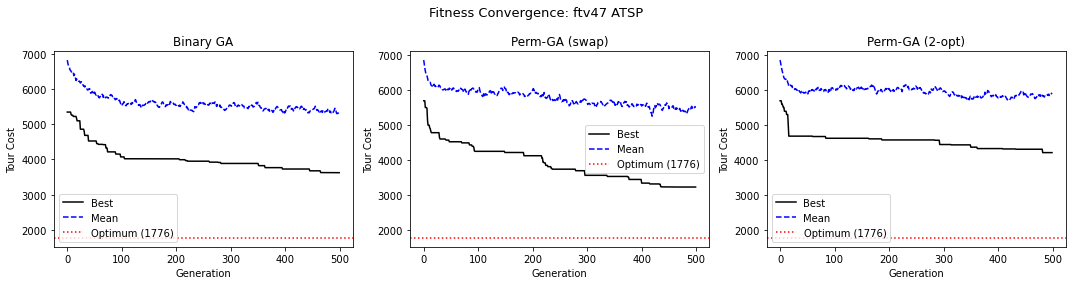

In [24]:
import matplotlib.pyplot as plt

print("=" * 55)
print("  COMPARISON OF ALL METHODS")
print("=" * 55)
results = {
    "Binary GA (genemap=Permutation)" : best_bin_cost,
    "Perm-GA (swap mutation)"         : cost_perm_swap,
    "Perm-GA (2-opt mutation)"        : cost_perm_2opt,
    "Perm-GA (greedy mutation)"       : cost_perm_greedy,
    "Greedy Heuristic"                : cost_greedy,
    "Best Greedy Heuristic"           : cost_best_greedy,
    "Lin-Kernighan (2-opt)"           : cost_lk,
}
for method, cost in sorted(results.items(), key=lambda x: x[1]):
    print(f"  {method:40s}  {cost:6d}")
print("=" * 55)
print(f"  Known optimum (ftv47): 1776")
print("=" * 55)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, stats, title in zip(
    axes,
    [stats_bin, stats_swap, stats_2opt],
    ["Binary GA", "Perm-GA (swap)", "Perm-GA (2-opt)"]
):
    ax.plot([s["min"]  for s in stats], label="Best",  color="black")
    ax.plot([s["mean"] for s in stats], label="Mean",  color="blue", linestyle="--")
    ax.axhline(y=1776, color="red", linestyle=":", label="Optimum (1776)")
    ax.set_title(title)
    ax.set_xlabel("Generation")
    ax.set_ylabel("Tour Cost")
    ax.legend()

plt.suptitle("Fitness Convergence: ftv47 ATSP", fontsize=13)
plt.tight_layout()
plt.show()